# 2 · Model training

**Goal:** train the two-stage model the service uses, and measure it honestly.

* **Stage 1** predicts attendance from the 67 features.
* **Stage 2** predicts whether the sponsorship is feasible, using the 67 features **plus stage 1's prediction**, because crowd size is the biggest driver of whether a deal pays off.

Steps: split by event → scale → compare models for each stage → evaluate → train on all data → save the models and their manifest.

In [1]:
import platform
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             mean_absolute_error, r2_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

sys.path.insert(0, ".")
from sponsorwise_ml.model_store import ARTIFACT_FILES, sha256_of, write_manifest

SEED = 42
MODEL_VERSION = "sponsorwise-xgb-1.0"
plt.rcParams["figure.figsize"] = (9, 4)

## 1. Load the features

In [2]:
data = pd.read_csv("mp_sponsorwise_ml_features.csv")
X = data.drop(columns=["actual_attendance", "feasible_to_sponsor"])
y_attendance = data["actual_attendance"]
y_feasible = data["feasible_to_sponsor"]

# The feature file has no event_id, but it is row-aligned with the raw file
event_ids = pd.read_csv("mp_sponsorwise_dataset.csv", usecols=["event_id"])["event_id"]
print("Rows:", len(X), "| features:", X.shape[1], "| events:", event_ids.nunique())

Rows: 70000 | features: 67 | events: 10000


## 2. Split by event, not by row

Each event appears 7 times (once per brand). A random split would put the same event in both training and testing, so the model would be tested on events it has already seen. `GroupShuffleSplit` keeps all 7 rows of an event on the same side.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, groups=event_ids))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
att_train, att_test = y_attendance.iloc[train_idx], y_attendance.iloc[test_idx]
feas_train, feas_test = y_feasible.iloc[train_idx], y_feasible.iloc[test_idx]
groups_train = event_ids.iloc[train_idx]

shared_events = set(event_ids.iloc[train_idx]) & set(event_ids.iloc[test_idx])
print(f"Train rows: {len(X_train):,} | test rows: {len(X_test):,} | events in both: {len(shared_events)}")

Train rows: 56,000 | test rows: 14,000 | events in both: 0


Scaling puts every feature on a similar range. Tree models don't need it, but the linear models in the comparison do, so one scaler is used for all. It is fitted on training data only.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Stage 1: compare attendance models

In [5]:
regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1, verbose=-1),
}

rows = []
for name, model in regressors.items():
    model.fit(X_train_scaled, att_train)
    predicted = model.predict(X_test_scaled)
    rows.append({"Model": name, "R²": r2_score(att_test, predicted), "MAE (people)": mean_absolute_error(att_test, predicted)})

regression_results = pd.DataFrame(rows).sort_values("R²", ascending=False).round(4)
regression_results

,Model,R²,MAE (people)
4,LightGBM,0.9299,2071.7405
3,XGBoost,0.9286,2089.3255
2,Random Forest,0.9142,2294.9350
0,Linear Regression,0.9114,2667.4180
1,Decision Tree,0.8772,2685.9939


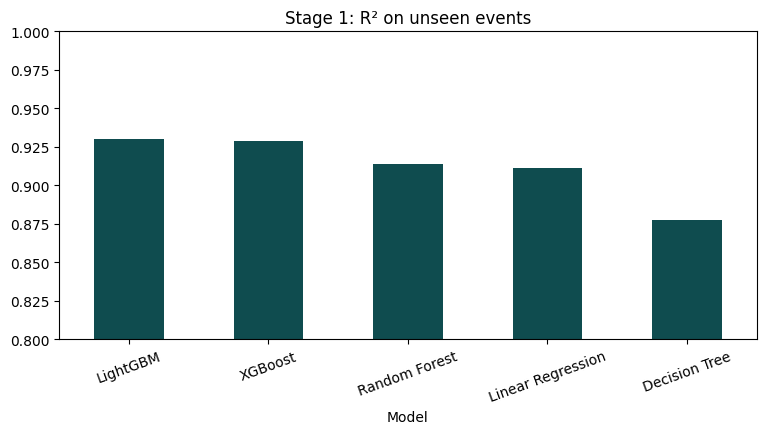

In [6]:
regression_results.plot.bar(x="Model", y="R²", legend=False, color="#0F4C4F", title="Stage 1: R² on unseen events")
plt.ylim(0.8, 1.0)
plt.xticks(rotation=20)
plt.show()

**Choice: XGBoost.** LightGBM is ahead by about 0.001 R², which is noise. Using XGBoost for both stages keeps one library, one tuning approach and one saved-model format.

## 4. Out-of-fold predictions for stage 2

Stage 2 learns from stage 1's predictions. If those came from a model that had already seen the same rows, they would be unrealistically accurate and stage 2 would trust them too much. `cross_val_predict` with `GroupKFold` gives every training row a prediction from a model that **never saw that event**, which is exactly what happens for a new event in production.

In [7]:
attendance_model = XGBRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)

oof_attendance = cross_val_predict(attendance_model, X_train_scaled, att_train,
                                   groups=groups_train, cv=GroupKFold(n_splits=5), n_jobs=-1)
attendance_model.fit(X_train_scaled, att_train)
test_attendance = attendance_model.predict(X_test_scaled)

stage1_r2 = r2_score(att_test, test_attendance)
stage1_mae = mean_absolute_error(att_test, test_attendance)
print(f"Stage 1 on unseen events: R² = {stage1_r2:.4f}, MAE = {stage1_mae:,.0f} people")

Stage 1 on unseen events: R² = 0.9221, MAE = 2,231 people


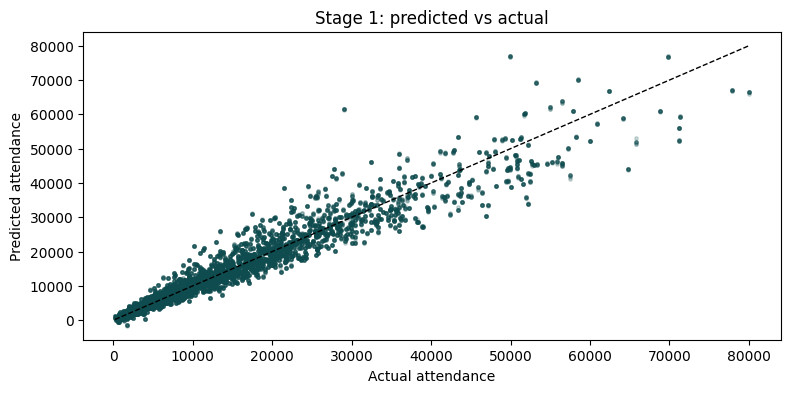

In [8]:
plt.scatter(att_test, test_attendance, alpha=0.2, s=6, color="#0F4C4F")
limits = [att_test.min(), att_test.max()]
plt.plot(limits, limits, "k--", lw=1)
plt.xlabel("Actual attendance")
plt.ylabel("Predicted attendance")
plt.title("Stage 1: predicted vs actual")
plt.show()

## 5. Stage 2: compare feasibility models

In [9]:
X_train_stage2 = np.column_stack((X_train_scaled, oof_attendance))
X_test_stage2 = np.column_stack((X_test_scaled, test_attendance))

# About 1 feasible deal for every 1.9 that aren't: weight the minority class by that ratio
class_weight = (feas_train == 0).sum() / (feas_train == 1).sum()
print(f"Negatives per positive: {class_weight:.3f}")

Negatives per positive: 1.892


In [10]:
classifiers = {
    # The appended attendance column isn't scaled yet, and logistic regression needs scaled inputs
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced",
                                            random_state=SEED, n_jobs=-1),
    "XGBoost (weight guessed as 10)": XGBClassifier(scale_pos_weight=10, random_state=SEED, n_jobs=-1),
    "XGBoost (weight = class ratio)": XGBClassifier(scale_pos_weight=class_weight, random_state=SEED, n_jobs=-1),
}

rows = []
for name, model in classifiers.items():
    model.fit(X_train_stage2, feas_train)
    predicted = model.predict(X_test_stage2)
    rows.append({"Model": name, "Accuracy": accuracy_score(feas_test, predicted),
                 "F1 (feasible)": f1_score(feas_test, predicted)})

classification_results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).round(4)
classification_results

,Model,Accuracy,F1 (feasible)
3,XGBoost (weight = class ratio),0.8063,0.7262
1,Random Forest,0.8050,0.7240
0,Logistic Regression,0.7776,0.7172
2,XGBoost (weight guessed as 10),0.6206,0.6254


Guessing the class weight as 10 overcorrects: the model calls far too many deals feasible. With the real class ratio, XGBoost matches Random Forest, so it is kept for consistency with stage 1.

## 6. Evaluate the chosen stage 2 model

In [11]:
feasibility_model = classifiers["XGBoost (weight = class ratio)"]
test_labels = feasibility_model.predict(X_test_stage2)
test_probabilities = feasibility_model.predict_proba(X_test_stage2)[:, 1]

stage2_accuracy = accuracy_score(feas_test, test_labels)
stage2_f1 = f1_score(feas_test, test_labels)
stage2_auc = roc_auc_score(feas_test, test_probabilities)
print(classification_report(feas_test, test_labels, target_names=["Not feasible", "Feasible"]))
print(f"ROC-AUC: {stage2_auc:.3f}")

              precision    recall  f1-score   support

Not feasible       0.85      0.85      0.85      9053
    Feasible       0.73      0.73      0.73      4947

    accuracy                           0.81     14000
   macro avg       0.79      0.79      0.79     14000
weighted avg       0.81      0.81      0.81     14000

ROC-AUC: 0.855


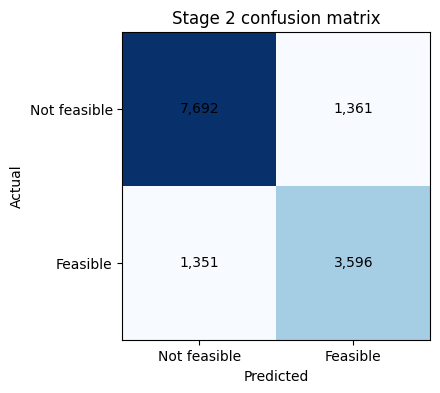

In [12]:
matrix = confusion_matrix(feas_test, test_labels)
plt.imshow(matrix, cmap="Blues")
for (row, column), count in np.ndenumerate(matrix):
    plt.text(column, row, f"{count:,}", ha="center", va="center", color="black")
plt.xticks([0, 1], ["Not feasible", "Feasible"])
plt.yticks([0, 1], ["Not feasible", "Feasible"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stage 2 confusion matrix")
plt.show()

The service turns probabilities into bands people understand: HIGH (≥ 60%), MEDIUM (≥ 35%), LOW (≥ 15%), UNLIKELY. This is how unseen deals fall into them:

In [13]:
bands = pd.cut(test_probabilities, bins=[0, 0.15, 0.35, 0.60, 1.0], include_lowest=True,
              labels=["UNLIKELY", "LOW", "MEDIUM", "HIGH"])
band_table = pd.DataFrame({"band": bands, "actually feasible": feas_test.values})
band_table.groupby("band", observed=True)["actually feasible"].agg(["count", "mean"]).round(3)

,count,mean
band,,
UNLIKELY,3447,0.091
LOW,4162,0.152
MEDIUM,2113,0.311
HIGH,4278,0.782


Higher bands really do contain more feasible deals, so the bands are meaningful.

### What the models rely on

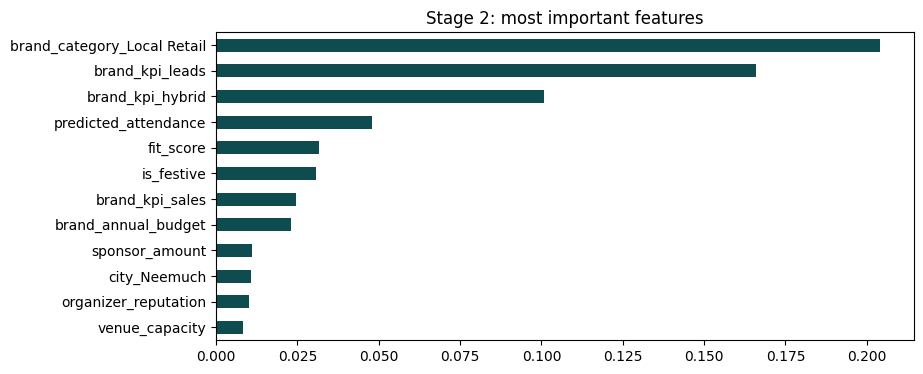

In [14]:
stage2_columns = list(X.columns) + ["predicted_attendance"]
importance = pd.Series(feasibility_model.feature_importances_, index=stage2_columns)
importance.sort_values().tail(12).plot.barh(color="#0F4C4F", title="Stage 2: most important features")
plt.show()

## 7. Train the final models on all the data

The test split was for measuring. The deployed models learn from every event, with the same out-of-fold trick between the stages. With fixed seeds and the pinned library versions in `requirements.txt`, re-running this produces identical models.

In [15]:
final_scaler = StandardScaler()
X_all_scaled = final_scaler.fit_transform(X)

final_attendance_model = XGBRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
oof_all = cross_val_predict(final_attendance_model, X_all_scaled, y_attendance,
                            groups=event_ids, cv=GroupKFold(n_splits=5), n_jobs=-1)
final_attendance_model.fit(X_all_scaled, y_attendance)

final_class_weight = (y_feasible == 0).sum() / (y_feasible == 1).sum()
final_feasibility_model = XGBClassifier(scale_pos_weight=final_class_weight, random_state=SEED, n_jobs=-1)
final_feasibility_model.fit(np.column_stack((X_all_scaled, oof_all)), y_feasible)
print(f"Final class weight: {final_class_weight:.4f}")

Final class weight: 1.8790


## 8. Save the models and their manifest

`model_manifest.json` records each file's SHA-256 fingerprint, the exact feature list, the metrics above and the library versions. The service refuses to load any model file whose fingerprint doesn't match, because loading a tampered pickle could run code.

In [16]:
output = Path(".")
joblib.dump(final_scaler, output / ARTIFACT_FILES["scaler"])
joblib.dump(final_attendance_model, output / ARTIFACT_FILES["attendance_model"])
joblib.dump(final_feasibility_model, output / ARTIFACT_FILES["feasibility_model"])

manifest = write_manifest(output, MODEL_VERSION, list(X.columns), training={
    "dataset": {
        "raw_file_sha256": sha256_of(Path("mp_sponsorwise_dataset.csv")),
        "feature_file_sha256": sha256_of(Path("mp_sponsorwise_ml_features.csv")),
        "rows": int(len(X)),
        "events": int(event_ids.nunique()),
        "feasible_rate": round(float(y_feasible.mean()), 4),
    },
    "evaluation": {
        "split": "GroupShuffleSplit by event_id, 20% of events held out",
        "stage1_attendance": {"r2": round(stage1_r2, 4), "mae": round(stage1_mae, 1)},
        "stage2_feasibility": {"accuracy": round(stage2_accuracy, 4), "f1_feasible": round(stage2_f1, 4),
                               "roc_auc": round(stage2_auc, 4)},
    },
    "parameters": {
        "seed": SEED,
        "stage1": "XGBRegressor(n_estimators=100)",
        "stage2": "XGBClassifier(scale_pos_weight=negatives/positives)",
        "stage2_class_weight": round(float(final_class_weight), 4),
        "stage2_input": "67 scaled features + out-of-fold stage 1 prediction",
    },
    "libraries": {"python": platform.python_version(), "xgboost": xgboost.__version__,
                  "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
})
print("Saved models", MODEL_VERSION)
{name: details["sha256"][:12] for name, details in manifest["artifacts"].items()}

Saved models sponsorwise-xgb-1.0


{'scaler': '5fab3c004f7a',
 'attendance_model': '19cece85361d',
 'feasibility_model': 'ccd68b72859c'}

## 9. Sanity check: reload and predict

In [17]:
reloaded_scaler = joblib.load(ARTIFACT_FILES["scaler"])
reloaded_attendance = joblib.load(ARTIFACT_FILES["attendance_model"])
sample = reloaded_scaler.transform(X.head(3))
print("Predicted attendance for 3 rows:", reloaded_attendance.predict(sample).round(0))
print("Actual:", y_attendance.head(3).tolist())

Predicted attendance for 3 rows: [6996. 6982. 6985.]
Actual: [6865, 6865, 6865]
